# Partie 1 : modèles de base entraînés de zéro

- 1.2 CNN-Plain : 6 couches de convolution, calcul des dimensions à la main, vérification avec `torchinfo`
- 1.3 CNN-Res : même profondeur avec des connexions résiduelles et un GAP
- 1.4 Étude d'un hyperparamètre : le learning rate
- 1.5 Norme du gradient par couche
- 1.6 Tableau comparatif

Images en 128×128. La partie 1.1 (exploration et découpage) est dans le notebook 00.

- On ajoute le dossier du projet au chemin Python pour importer notre code (`src/`).
- `config` contient les chemins, la classe M choisie et le GPU utilisé.
- `set_seed(42)` fixe le hasard : on obtient les mêmes résultats à chaque exécution.
- La dernière ligne affiche la machine utilisée.

In [1]:
import sys
from pathlib import Path

#dossier du projet pour pouvoir importer src/
sys.path.insert(0, str(Path.cwd().parent))

from src import config as C
C.set_seed(42)
print(C.describe_env())

Python 3.12.10, torch 2.6.0+cu124, torchvision 0.21.0+cu124
Calcul sur : cuda
GPU : NVIDIA GeForce RTX 4080 Laptop GPU
CPU : 13th Gen Intel(R) Core(TM) i7-13650HX (20 coeurs logiques)


- On relit le découpage `splits.csv` et la normalisation calculée sur le train (notebook 00).
- `clf_loaders` prépare les images en 128×128 pour train, val et test. Sur le train seulement, on ajoute des retournements et rotations de 90° au hasard (augmentation de données).
- La perte est l'entropie croisée pondérée par classe, à cause du déséquilibre.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torchinfo import summary

from src import data as D
from src.models import CNNPlain, CNNRes
from src.train import fit, load_best
from src.metrics import (predict, clf_report, plot_confusion, plot_histories, count_params, model_size_mb, upsert_summary, savefig)

df = D.load_splits()
norm = D.norm_stats("scratch")
loaders = D.clf_loaders(df, D.CLASSES, C.SCRATCH_SIZE, norm, batch_size=64)
for nom, l in loaders.items():
    print(nom, len(l.dataset), "images")

poids = D.class_weights(loaders["train"].dataset.labels, len(D.CLASSES)).to(C.DEVICE)
criterion = nn.CrossEntropyLoss(weight=poids)
NOMS = [D.short(c) for c in D.CLASSES]

train 12711 images
val 2724 images
test 2725 images


## 1.2 CNN-Plain

Architecture : 3 étages de 2 blocs Conv-BN-ReLU, un MaxPool 2×2 après chaque étage, puis Flatten, Dense(32)-BN-ReLU, Dropout(0,3), Dense(10).

### Calcul des dimensions à la main

Une image ou une carte a pour dimensions $W \times H \times D$ (largeur, hauteur, profondeur).

- Convolution, 4 hyperparamètres $K$ (nombre de filtres), $F$ (taille), $S$ (pas), $P$ (zero-padding) :
  $W_c = \frac{W - F + 2P}{S} + 1$, $\quad H_c = \frac{H - F + 2P}{S} + 1$, $\quad D_c = K$
- Pooling, 2 hyperparamètres $F$ et $S$ : $W_p = \frac{W - F}{S} + 1$, $\quad H_p = \frac{H - F}{S} + 1$, $\quad D_p = D$
- Paramètres d'une convolution : $F \times F \times D \times K$ poids (+ $K$ biais)

On applique la règle du cours $P = \frac{F - 1}{2}$ avec $S = 1$ : avec $F = 3$, $P = 1$, on obtient $W_c = \frac{W - 3 + 2}{1} + 1 = W$, la taille est conservée. Seul le pooling ($F = 2$, $S = 2$) divise la taille par 2.

Les convolutions n'ont pas de biais, car la BatchNorm qui suit en a déjà un ($\beta$). Chaque BatchNorm ajoute $2K$ paramètres ($\gamma$ et $\beta$). Les images sont carrées, donc $H = W$ partout.

| Couche | Calcul | Sortie $W \times H \times D$ | Paramètres |
|---|---|---|---|
| Entrée | | 128 × 128 × 3 | 0 |
| Conv1 (K=32, F=3, S=1, P=1) + BN | $W_c$ = (128 − 3 + 2)/1 + 1 = 128, $D_c$ = 32 | 128 × 128 × 32 | 3×3×3×32 = 864, + 64 |
| Conv2 (K=32) + BN | 128 | 128 × 128 × 32 | 3×3×32×32 = 9 216, + 64 |
| MaxPool (F=2, S=2) | $W_p$ = (128 − 2)/2 + 1 = 64, $D_p$ = 32 | 64 × 64 × 32 | 0 |
| Conv3 (K=64) + BN | 64 | 64 × 64 × 64 | 3×3×32×64 = 18 432, + 128 |
| Conv4 (K=64) + BN | 64 | 64 × 64 × 64 | 3×3×64×64 = 36 864, + 128 |
| MaxPool (F=2, S=2) | (64 − 2)/2 + 1 = 32 | 32 × 32 × 64 | 0 |
| Conv5 (K=128) + BN | 32 | 32 × 32 × 128 | 3×3×64×128 = 73 728, + 256 |
| Conv6 (K=128) + BN | 32 | 32 × 32 × 128 | 3×3×128×128 = 147 456, + 256 |
| MaxPool (F=2, S=2) | (32 − 2)/2 + 1 = 16 | 16 × 16 × 128 | 0 |
| Flatten | 16 × 16 × 128 | 32 768 | 0 |
| Dense 32 | | 32 | 32 768 × 32 + 32 = 1 048 608 |
| BN + ReLU | | 32 | 2 × 32 = 64 |
| Dropout 0,3 | | 32 | 0 |
| Dense 10 (softmax dans la perte) | | 10 | 32 × 10 + 10 = 330 |
| **Total** | | | **1 336 458** |

Remarque : `torchinfo` affiche les tailles dans l'ordre de PyTorch, $D \times H \times W$ (par exemple `[1, 32, 128, 128]`). Ce sont les mêmes nombres dans un autre ordre.

### Pourquoi ces choix

- **Noyaux 3×3** (idée de VGG, cours architectures) : deux 3×3 à la suite voient la même zone qu'un 5×5, avec moins de poids (2 × 9 = 18 au lieu de 25 par couple de canaux) et une ReLU de plus, donc une fonction plus riche.
- **Padding 1** : la taille est gardée dans chaque étage, seul le pooling la réduit (128, 64, 32, 16).
- **Filtres doublés (32, 64, 128)** à chaque fois que la taille est divisée par 2 : comme dans VGG, « espace qui diminue, canaux qui augmentent ».
- **Dense de 32 neurones** : après le Flatten il y a 32 768 valeurs, donc chaque neurone coûte 32 768 poids. La tête représente déjà 78 % du modèle.
- **BatchNorm après la Dense** : lors d'un premier essai sans elle, 30 neurones sur 32 de cette couche étaient « morts » (leur ReLU donnait 0 pour toutes les images) et le modèle plafonnait à 46 % de F1. La couche reçoit 32 768 valeurs d'un coup : sans normalisation, les sommes sont grandes et Adam pousse vite les neurones dans la zone où la ReLU vaut 0. La BatchNorm recentre ces sommes, comme dans les blocs Conv-BN-ReLU.
- **Dropout 0,3** dans la tête, la partie qui sur-apprend le plus facilement.

- `torchinfo` affiche la taille de sortie et le nombre de paramètres de chaque couche. On vérifie qu'on retrouve le tableau calculé à la main (total 1 336 458).

In [3]:
summary(CNNPlain(10), input_size=(1, 3, 128, 128), col_names=("output_size", "num_params"), depth=3)

Layer (type:depth-idx)                   Output Shape              Param #
CNNPlain                                 [1, 10]                   --
├─Sequential: 1-1                        [1, 128, 16, 16]          --
│    └─Sequential: 2-1                   [1, 32, 128, 128]         --
│    │    └─Conv2d: 3-1                  [1, 32, 128, 128]         864
│    │    └─BatchNorm2d: 3-2             [1, 32, 128, 128]         64
│    │    └─ReLU: 3-3                    [1, 32, 128, 128]         --
│    └─Sequential: 2-2                   [1, 32, 128, 128]         --
│    │    └─Conv2d: 3-4                  [1, 32, 128, 128]         9,216
│    │    └─BatchNorm2d: 3-5             [1, 32, 128, 128]         64
│    │    └─ReLU: 3-6                    [1, 32, 128, 128]         --
│    └─MaxPool2d: 2-3                    [1, 32, 64, 64]           --
│    └─Sequential: 2-4                   [1, 64, 64, 64]           --
│    │    └─Conv2d: 3-7                  [1, 64, 64, 64]           18,432
│    │ 

## 1.3 CNN-Res

On garde 6 convolutions 3×3, mais regroupées en 3 **blocs résiduels** (on s'est basé sur le tp2, exo7), chacun suivi d'un MaxPool. Dans un bloc résiduel, on additionne l'entrée du bloc à sa sortie : $y = F(x) + x$, où $F$ = Conv-BN-ReLU-Conv-BN. Comme dans le cours, une BatchNorm suit chaque convolution. Quand le nombre de canaux change, l'addition directe est impossible : on met une convolution 1×1 sur le raccourci (**raccourci par projection**), $y = F(x) + W_s x$.

On remplace Flatten + Dense par un **Global Average Pooling (GAP)** (comme tp2, exo 6) : chaque carte est résumée par sa moyenne, donc la tête n'a plus que 256 × 10 + 10 = 2 570 paramètres.

**Budget comparable.** Avec les mêmes largeurs que CNN-Plain (32, 64, 128), CNN-Res n'aurait que 0,3 M de paramètres, parce que le GAP supprime la grosse couche dense. On élargit donc à 64, 128, 256 filtres pour arriver à un nombre de paramètres du même ordre :

| Bloc | Sortie après pool ($W \times H \times D$) | Paramètres (convolutions + raccourci 1×1 + BN) |
|---|---|---|
| Bloc 1 (3 → 64) | 64 × 64 × 64 | 1 728 + 36 864 + 192 + 384 = 39 168 |
| Bloc 2 (64 → 128) | 32 × 32 × 128 | 73 728 + 147 456 + 8 192 + 768 = 230 144 |
| Bloc 3 (128 → 256) | 16 × 16 × 256 | 294 912 + 589 824 + 32 768 + 1 536 = 919 040 |
| GAP + Dropout + Dense 10 | 10 | 2 570 |
| **Total** | | **1 190 922** |

CNN-Plain : 1,34 M paramètres. CNN-Res : 1,19 M. Même ordre de grandeur, mais CNN-Plain met ses paramètres dans la tête dense, CNN-Res dans les convolutions.

- Vérification du tableau de CNN-Res avec `torchinfo` (total 1 190 922).

In [4]:
summary(CNNRes(10), input_size=(1, 3, 128, 128), col_names=("output_size", "num_params"), depth=3)

Layer (type:depth-idx)                   Output Shape              Param #
CNNRes                                   [1, 10]                   --
├─Sequential: 1-1                        [1, 256, 16, 16]          --
│    └─ResidualBlock: 2-1                [1, 64, 128, 128]         --
│    │    └─Conv2d: 3-1                  [1, 64, 128, 128]         1,728
│    │    └─BatchNorm2d: 3-2             [1, 64, 128, 128]         128
│    │    └─Conv2d: 3-3                  [1, 64, 128, 128]         36,864
│    │    └─BatchNorm2d: 3-4             [1, 64, 128, 128]         128
│    │    └─Sequential: 3-5              [1, 64, 128, 128]         320
│    └─MaxPool2d: 2-2                    [1, 64, 64, 64]           --
│    └─ResidualBlock: 2-3                [1, 128, 64, 64]          --
│    │    └─Conv2d: 3-6                  [1, 128, 64, 64]          73,728
│    │    └─BatchNorm2d: 3-7             [1, 128, 64, 64]          256
│    │    └─Conv2d: 3-8                  [1, 128, 64, 64]          147

### Entraînement des deux modèles

Mêmes réglages pour les deux : Adam, learning rate 0,001, batch 64, 15 époques, perte pondérée. À chaque époque on garde le modèle s'il a le meilleur F1 macro sur la **validation**. On enregistre aussi la norme du gradient de chaque convolution toutes les 20 itérations (pour la partie 1.5).

- La fonction `entrainer` remet la graine à 42, crée le modèle et l'optimiseur Adam, puis lance `fit`.
- `fit` entraîne le modèle et enregistre pour chaque époque : perte et accuracy en train et en validation, F1 de validation, temps. Les fichiers vont dans `results/runs/` et les poids dans `results/ckpt/`.
- On entraîne CNN-Plain puis CNN-Res avec exactement les mêmes réglages.

In [5]:
EPOCHS = C.ep(15)

def entrainer(nom, creer_modele, lr, epochs, grad_every=None):
    C.set_seed(42)                     # même initialisation pour toutes les expériences
    model = creer_modele().to(C.DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    meta = {"arch": nom.split("_lr")[0], "classes": D.CLASSES, "size": 128, "lr": lr, "epochs": epochs}
    historique = fit(model, loaders, epochs, optimizer, criterion, nom, meta, grad_every=grad_every)
    return model, historique

plain, h_plain = entrainer("cnn_plain", lambda: CNNPlain(10), 1e-3, EPOCHS, grad_every=20)
res, h_res = entrainer("cnn_res", lambda: CNNRes(10), 1e-3, EPOCHS, grad_every=20)

[cnn_plain] ep 1/15 | loss 1.1822/0.6507 | acc 0.7018/0.8374 | F1 val 0.7955 | 21s
[cnn_plain] ep 2/15 | loss 0.6882/0.5686 | acc 0.8139/0.8131 | F1 val 0.7986 | 15s
[cnn_plain] ep 3/15 | loss 0.5458/0.3901 | acc 0.8376/0.8715 | F1 val 0.8411 | 15s
[cnn_plain] ep 4/15 | loss 0.4702/0.2578 | acc 0.8591/0.9218 | F1 val 0.9029 | 15s
[cnn_plain] ep 5/15 | loss 0.4188/0.2197 | acc 0.8703/0.9365 | F1 val 0.9233 | 15s
[cnn_plain] ep 6/15 | loss 0.3464/0.1978 | acc 0.8943/0.9380 | F1 val 0.9238 | 15s
[cnn_plain] ep 7/15 | loss 0.3273/0.2267 | acc 0.9008/0.9266 | F1 val 0.9202 | 15s
[cnn_plain] ep 8/15 | loss 0.2955/0.2176 | acc 0.9091/0.9269 | F1 val 0.9161 | 15s
[cnn_plain] ep 9/15 | loss 0.2565/0.1507 | acc 0.9177/0.9530 | F1 val 0.9467 | 15s
[cnn_plain] ep 10/15 | loss 0.2346/0.1825 | acc 0.9257/0.9398 | F1 val 0.9322 | 15s
[cnn_plain] ep 11/15 | loss 0.2293/0.1332 | acc 0.9278/0.9545 | F1 val 0.9470 | 15s
[cnn_plain] ep 12/15 | loss 0.1956/0.1354 | acc 0.9363/0.9593 | F1 val 0.9547 | 15s
[

- Si la courbe de train continue de s'améliorer pendant que celle de validation stagne ou se dégrade, le modèle sur-apprend.

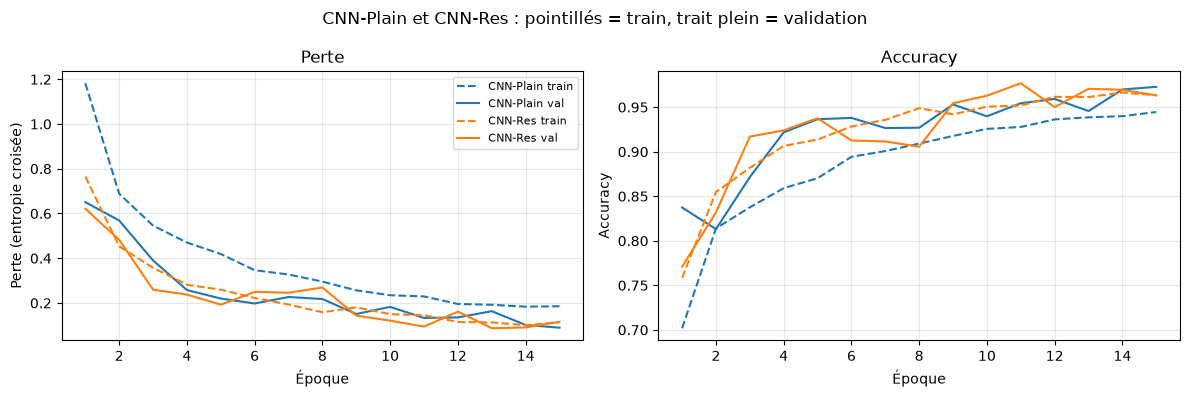

In [6]:
plot_histories({"CNN-Plain": h_plain, "CNN-Res": h_res}, path=C.FIG_DIR / "01_courbes_plain_res.png",
               title="CNN-Plain et CNN-Res : pointillés = train, trait plein = validation")

**Analyse.**

- Aucun des deux modèles ne sur-apprend en 15 époques : la perte de validation continue de baisser avec celle du train et les deux courbes restent proches. L'accuracy de train est même un peu sous celle de validation (0,94 contre 0,97 pour CNN-Plain à la fin) : c'est normal, car en train les images sont augmentées (retournements, rotations) et le Dropout est actif, ce qui rend la tâche plus difficile qu'en validation.
- CNN-Res apprend plus vite au début : 0,917 d'accuracy de validation dès l'époque 3, contre 0,87 pour CNN-Plain. À la fin, les deux sont très proches (meilleur F1 de validation 0,974 pour CNN-Res, 0,971 pour CNN-Plain).
- Premier essai de CNN-Plain, sans BatchNorm après la couche Dense : le modèle plafonnait à 0,46 de F1, avec une accuracy de train (0,47) inférieure à celle de validation (0,60). En vérifiant les activations, 30 neurones sur 32 de la couche Dense étaient « morts » (ReLU toujours à 0). C'est un problème d'optimisation, pas de sur-apprentissage : la couche reçoit 32 768 valeurs d'un coup, et sans normalisation ses neurones basculent dans la zone où la ReLU vaut 0. Ajouter une BatchNorm (64 paramètres) a suffi à corriger le problème.

## 1.4 Étude d'un hyperparamètre : le learning rate

On reprend la grille du tp1 (exo 5) : CNN-Res avec 4 learning rates, 0,1, 0,01, 0,001 et 0,0001. Tout le reste est identique (Adam, 10 époques). On compare les courbes sur la validation ; le test n'est pas utilisé ici.

- Une boucle sur les 4 valeurs du learning rate ; chaque essai a son propre nom et ses propres fichiers.
- Chaque essai est ajouté au tableau récapitulatif `summary.csv` (avec le F1 de validation seulement).
- On superpose les courbes des 4 essais, puis on affiche le meilleur F1 de validation de chacun.

[cnn_res_lr0.1] ep 1/10 | loss 2.3180/1.9604 | acc 0.2812/0.2636 | F1 val 0.1967 | 22s
[cnn_res_lr0.1] ep 2/10 | loss 1.8550/1.5940 | acc 0.3767/0.4372 | F1 val 0.3510 | 22s
[cnn_res_lr0.1] ep 3/10 | loss 1.7276/1.5151 | acc 0.4125/0.4468 | F1 val 0.3599 | 22s
[cnn_res_lr0.1] ep 4/10 | loss 1.5433/1.4803 | acc 0.4766/0.4060 | F1 val 0.3834 | 22s
[cnn_res_lr0.1] ep 5/10 | loss 1.3466/1.5088 | acc 0.5413/0.4717 | F1 val 0.4327 | 22s
[cnn_res_lr0.1] ep 6/10 | loss 1.2775/1.1782 | acc 0.5709/0.6395 | F1 val 0.5555 | 22s
[cnn_res_lr0.1] ep 7/10 | loss 1.1785/0.9410 | acc 0.6080/0.6725 | F1 val 0.6555 | 22s
[cnn_res_lr0.1] ep 8/10 | loss 1.0717/0.9906 | acc 0.6394/0.7232 | F1 val 0.6872 | 22s
[cnn_res_lr0.1] ep 9/10 | loss 1.0368/1.0784 | acc 0.6564/0.6722 | F1 val 0.5660 | 23s
[cnn_res_lr0.1] ep 10/10 | loss 0.9742/0.7229 | acc 0.6805/0.7702 | F1 val 0.7465 | 24s
Reprise depuis l'époque 10
Reprise depuis l'époque 10
Reprise depuis l'époque 10


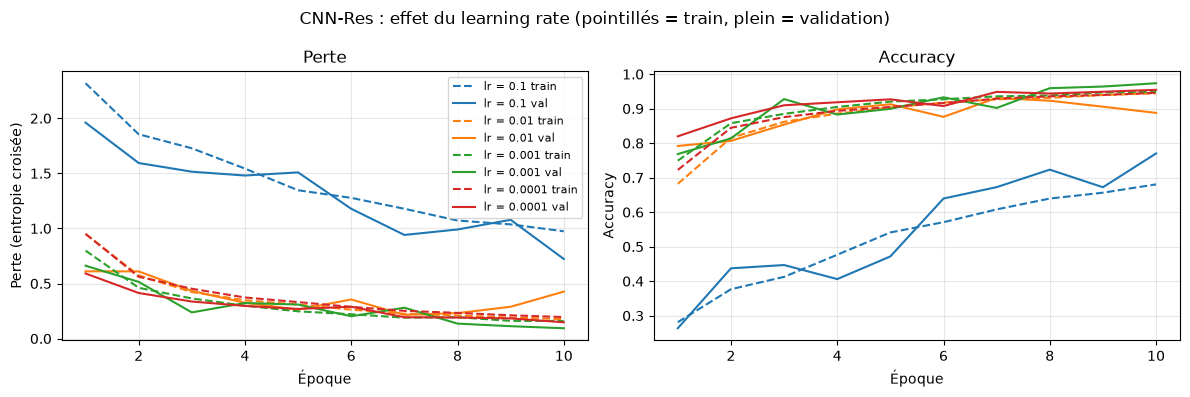

lr = 0.1 : meilleur F1 val = 0.7465 (époque 10), perte train finale = 0.9742
lr = 0.01 : meilleur F1 val = 0.9191 (époque 8), perte train finale = 0.1772
lr = 0.001 : meilleur F1 val = 0.9662 (époque 10), perte train finale = 0.1597
lr = 0.0001 : meilleur F1 val = 0.9524 (époque 10), perte train finale = 0.1955


In [7]:
historiques_lr = {}
for lr in [1e-1, 1e-2, 1e-3, 1e-4]:
    _, h = entrainer(f"cnn_res_lr{lr:g}", lambda: CNNRes(10), lr, C.ep(10))
    historiques_lr[f"lr = {lr:g}"] = h
    upsert_summary({"experiment": f"P1_CNN-Res_lr={lr:g}", "partie": 1, "modele": "CNN-Res",
                    "hyperparametres": f"Adam lr={lr:g}, batch 64, 10 époques",
                    "temps_entrainement_s": round(h.train_time_s.iloc[-1], 1), "val_f1": round(h.val_f1.max(), 4)})

plot_histories(historiques_lr, path=C.FIG_DIR / "01_etude_lr.png",
               title="CNN-Res : effet du learning rate (pointillés = train, plein = validation)")
for nom, h in historiques_lr.items():
    print(f"{nom} : meilleur F1 val = {h.val_f1.max():.4f} (époque {h.val_f1.idxmax() + 1}), "
          f"perte train finale = {h.train_loss.iloc[-1]:.4f}")

**Analyse.**

- **lr = 0,1, trop grand** : les pas de mise à jour sont trop grands, le modèle n'arrive pas à descendre correctement. Après 10 époques, la perte de train est encore à 0,97 et l'accuracy de validation à 0,77 seulement (F1 0,75), avec des remontées d'une époque à l'autre.
- **lr = 0,01, encore un peu grand** : le modèle apprend vite, mais la validation est instable. La perte de validation remonte en fin d'entraînement (0,43 à l'époque 10) alors que celle du train continue de baisser, et le F1 passe de 0,919 à 0,911.
- **lr = 0,001, le meilleur** : descente régulière et meilleur F1 de validation (0,966 à l'époque 10).
- **lr = 0,0001, trop petit** : courbes très régulières mais apprentissage plus lent ; la perte de train finale (0,196) est la plus haute des trois bons essais, et le modèle progresse encore à l'époque 10 (F1 0,952). Avec plus d'époques, il rattraperait sans doute 0,001.
- On garde donc lr = 0,001, choisi sur la validation.

## 1.5 Diagnostic de l'optimisation : norme du gradient par couche

Pendant l'entraînement, on a noté la norme du gradient de chaque convolution (couche 1 = la plus proche de l'image).

Dans un réseau sans raccourci, le gradient est multiplié couche après couche en remontant vers l'entrée. S'il est multiplié par des valeurs plus petites que 1, il devient très petit pour les premières couches : c'est le **vanishing gradient**, les premières couches apprennent mal.

Dans un bloc résiduel, $y = F(x) + x$, donc $\frac{\partial y}{\partial x} = \frac{\partial F}{\partial x} + 1$. Le cours parle d'une « autoroute » : même si $\frac{\partial F}{\partial x}$ est minuscule, le gradient revient vers les premières couches. Ici les raccourcis sont des projections 1×1 ($y = F(x) + W_s x$) car les canaux changent : le « + 1 » devient $W_s$, un chemin court d'une seule couche sans ReLU, qui joue le même rôle.

- Pour chaque modèle, on relit les normes enregistrées et on fait un tableau couche × itération.
- On l'affiche en carte de chaleur, en log10 parce que les valeurs vont de très petites à grandes.
- Une première ligne (conv1) plus sombre que la dernière (conv6) veut dire que le gradient est plus faible près de l'entrée.

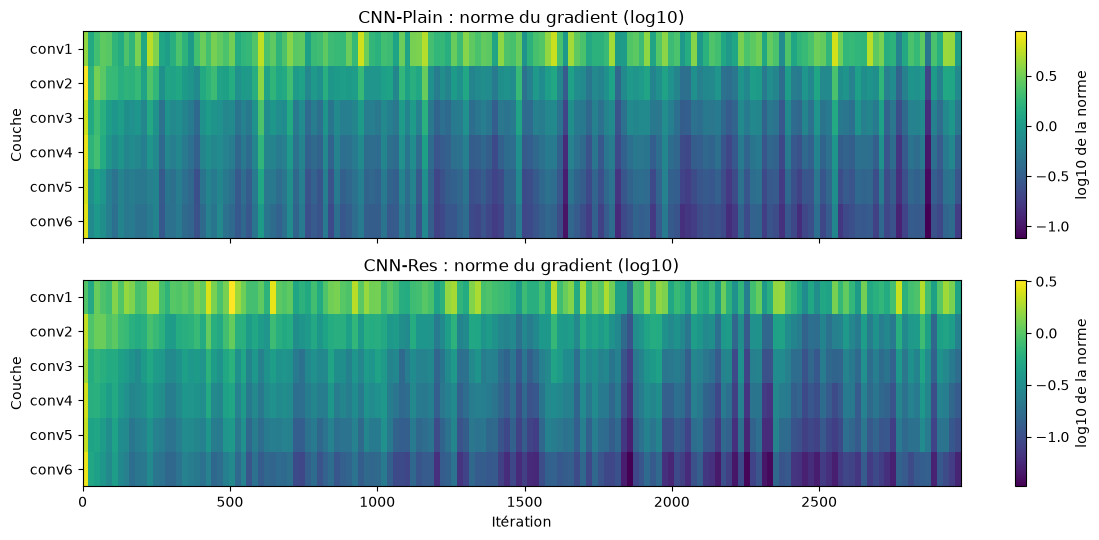

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
for ax, nom, titre in zip(axes, ["cnn_plain", "cnn_res"], ["CNN-Plain", "CNN-Res"]):
    g = pd.read_csv(C.RUNS_DIR / nom / "grad_norms.csv")
    tableau = g.pivot_table(index="layer_idx", columns="iter", values="grad_norm")
    image = ax.imshow(np.log10(tableau.values + 1e-12), aspect="auto", cmap="viridis",
                      extent=[tableau.columns.min(), tableau.columns.max(), 6.5, 0.5])
    ax.set_yticks(range(1, 7), [f"conv{i}" for i in range(1, 7)])
    ax.set_ylabel("Couche")
    ax.set_title(f"{titre} : norme du gradient (log10)")
    fig.colorbar(image, ax=ax, label="log10 de la norme")
axes[1].set_xlabel("Itération")
plt.tight_layout()
savefig("01_gradient_heatmap.png")
plt.show()

- Pour chaque couche, on prend la valeur médiane de la norme sur tout l'entraînement et on trace une courbe par modèle.
- Le rapport conv1 / conv6 résume le résultat : plus il est petit, plus le gradient s'affaiblit en remontant vers l'entrée.

CNN-Plain : gradient conv1 / gradient conv6 = 7.348
CNN-Res : gradient conv1 / gradient conv6 = 7.042


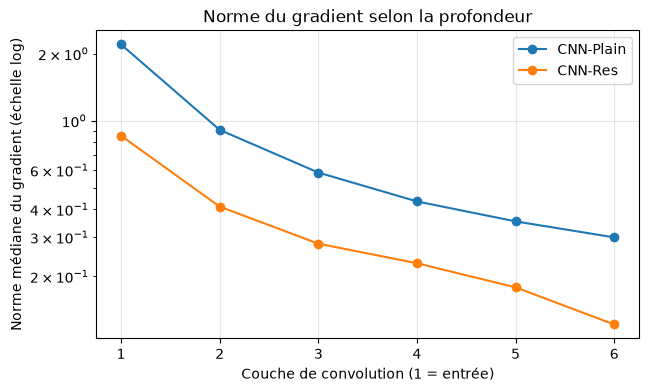

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for nom, titre in [("cnn_plain", "CNN-Plain"), ("cnn_res", "CNN-Res")]:
    g = pd.read_csv(C.RUNS_DIR / nom / "grad_norms.csv")
    mediane = g.groupby("layer_idx")["grad_norm"].median()
    ax.plot(mediane.index, mediane.values, "o-", label=titre)
    print(f"{titre} : gradient conv1 / gradient conv6 = {mediane.loc[1] / mediane.loc[6]:.3f}")
ax.set_yscale("log")
ax.set_xlabel("Couche de convolution (1 = entrée)")
ax.set_ylabel("Norme médiane du gradient (échelle log)")
ax.set_title("Norme du gradient selon la profondeur")
ax.legend()
ax.grid(alpha=0.3)
savefig("01_gradient_par_couche.png")
plt.show()

**Analyse.**

- On n'observe **pas** de disparition du gradient : dans les deux modèles, la norme du gradient est la plus grande pour la première couche et diminue vers la sixième (rapport conv1 / conv6 d'environ 7 pour les deux modèles). Les premières couches reçoivent donc bien un gradient.
- Explication : le réseau n'a que 6 couches, et chaque convolution est suivie d'une BatchNorm, qui remet les activations à une échelle stable et évite que le gradient s'écrase en remontant. Le cours le rappelle : ReLU, BatchNorm et connexions résiduelles sont trois leviers contre ce problème ; ici les deux premiers suffisent.
- Attention en lisant la figure : conv1 n'a que 864 poids alors que conv6 en a 147 456. La norme dépend aussi du nombre de poids, il ne faut donc pas sur-interpréter la pente.
- L'avantage des connexions résiduelles n'est pas visible sur la norme du gradient à cette profondeur. On le voit surtout sur la vitesse de convergence (CNN-Res meilleur dès les premières époques). Le « +1 » de $\frac{\partial y}{\partial x} = \frac{\partial F}{\partial x} + 1$ devient décisif sur des réseaux de plusieurs dizaines de couches, où apparaît la dégradation.

## 1.6 Évaluation sur le test et tableau comparatif

On évalue chaque modèle final **une seule fois** sur le test, avec ses meilleurs poids (choisis sur la validation).

- Pour chaque modèle : on recharge les meilleurs poids, on prédit le test, on calcule accuracy, F1 macro, rappel par classe et matrice de confusion.
- Les prédictions sont gardées dans `results/preds/` pour l'analyse d'erreurs.
- On ajoute une ligne par modèle dans `summary.csv`.
- Matrices de confusion : chaque ligne est une vraie classe ; la case sur la diagonale est le rappel de cette classe.

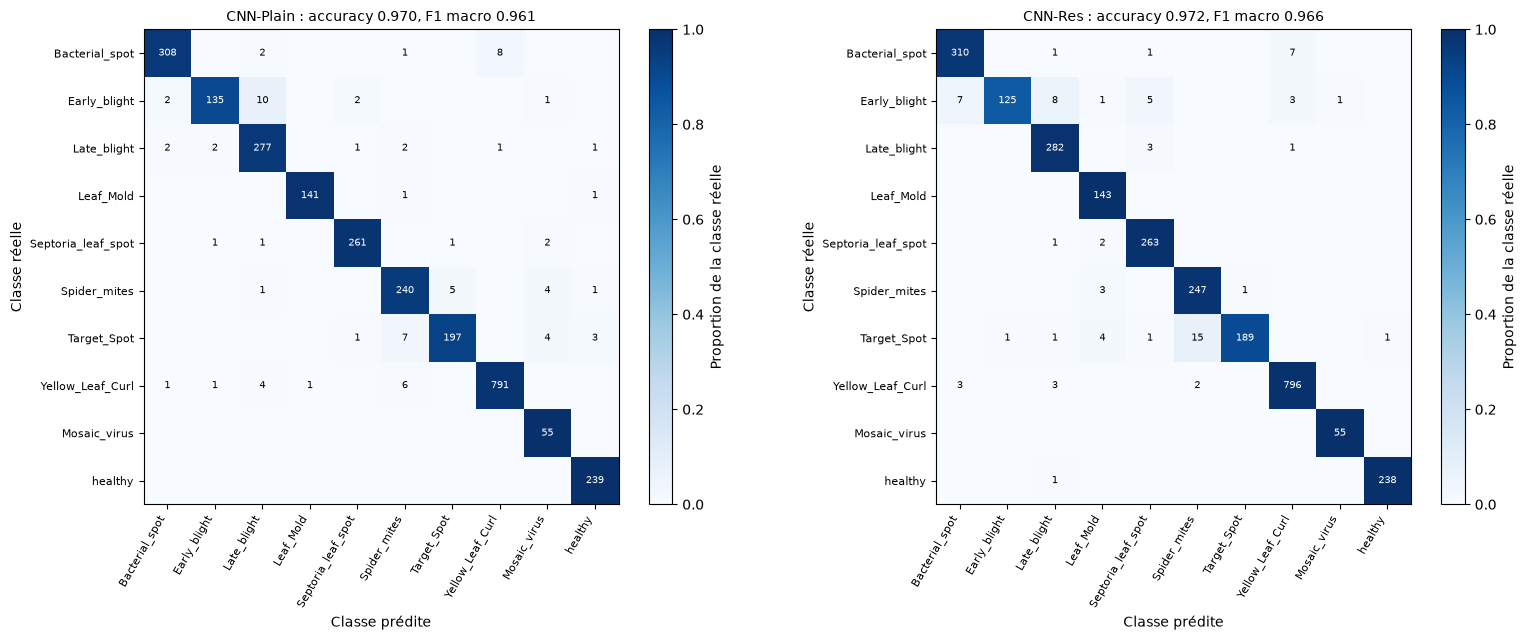

In [10]:
(C.RESULTS / "preds").mkdir(exist_ok=True)
rapports = {}
for nom, titre, model, h in [("cnn_plain", "CNN-Plain", plain, h_plain), ("cnn_res", "CNN-Res", res, h_res)]:
    model = load_best(model, nom)
    y_vrai, y_pred, proba = predict(model, loaders["test"])
    r = clf_report(y_vrai, y_pred, NOMS)
    rapports[titre] = r
    pd.DataFrame({"path": loaders["test"].dataset.df["path"], "y_true": y_vrai, "y_pred": y_pred,
                  "msp": proba.max(1)}).to_csv(C.RESULTS / "preds" / f"{nom}_test.csv", index=False)
    upsert_summary({"experiment": f"P1_{titre}", "partie": 1, "modele": titre, "resolution": 128,
                    "hyperparametres": f"Adam lr=0.001, batch 64, {EPOCHS} époques",
                    "params": count_params(model)[0], "taille_mo": round(model_size_mb(model), 2),
                    "temps_entrainement_s": round(h.train_time_s.iloc[-1], 1), "val_f1": round(h.val_f1.max(), 4),
                    "test_acc": round(r["acc"], 4), "test_f1_macro": round(r["f1_macro"], 4), "run": nom})

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (titre, r) in zip(axes, rapports.items()):
    plot_confusion(r["cm"], NOMS, f"{titre} : accuracy {r['acc']:.3f}, F1 macro {r['f1_macro']:.3f}", ax=ax)
plt.tight_layout()
savefig("01_matrices_confusion.png")
plt.show()

- Rappel par classe des deux modèles : on voit quelles maladies sont mal reconnues.
- Tableau comparatif demandé : paramètres, taille mémoire en Mo, temps d'entraînement, accuracy, F1 macro.

In [11]:
rappels = pd.DataFrame({titre: r["recall"] for titre, r in rapports.items()})
print("Rappel par classe sur le test :")
print(rappels.round(3))

tableau = pd.DataFrame({titre: {"paramètres": count_params(m)[0], "taille (Mo)": round(model_size_mb(m), 2),
                                "temps d'entraînement (s)": round(h.train_time_s.iloc[-1]),
                                "accuracy test": round(r["acc"], 4), "F1 macro test": round(r["f1_macro"], 4)}
                        for (titre, r), m, h in zip(rapports.items(), [plain, res], [h_plain, h_res])})
tableau

Rappel par classe sur le test :
                    CNN-Plain  CNN-Res
Bacterial_spot          0.966    0.972
Early_blight            0.900    0.833
Late_blight             0.969    0.986
Leaf_Mold               0.986    1.000
Septoria_leaf_spot      0.981    0.989
Spider_mites            0.956    0.984
Target_Spot             0.929    0.892
Yellow_Leaf_Curl        0.984    0.990
Mosaic_virus            1.000    1.000
healthy                 1.000    0.996


,CNN-Plain,CNN-Res
paramètres,1.336458e+06,1.190922e+06
taille (Mo),5.360000e+00,4.790000e+00
temps d'entraînement (s),2.320000e+02,3.590000e+02
accuracy test,9.703000e-01,9.717000e-01
F1 macro test,9.612000e-01,9.660000e-01


**Analyse.**

- À nombre de paramètres comparable (1,34 M contre 1,19 M), les deux modèles sont très proches sur le test : CNN-Res 0,972 d'accuracy et 0,966 de F1 macro, CNN-Plain 0,970 et 0,961. CNN-Res fait légèrement mieux avec moins de paramètres et un modèle plus léger (4,79 Mo contre 5,36 Mo).
- La différence vient de la répartition des paramètres : CNN-Plain en met 78 % dans sa couche Dense (1 048 608 poids juste pour relier le Flatten à 32 neurones), CNN-Res les met dans les convolutions grâce au GAP, qui ne coûte rien (TP2, exercice 6).
- CNN-Res est plus long à entraîner (359 s contre 232 s) : ses convolutions sont plus larges (64, 128, 256 filtres) et travaillent sur de grandes cartes, donc plus de calculs, même avec moins de paramètres.
- Classe la plus difficile pour les deux : **Early_blight** (rappel 0,90 pour CNN-Plain, 0,83 pour CNN-Res), souvent confondue avec Late_blight et Bacterial_spot. Ce sont des taches brunes qui se ressemblent. Pour CNN-Res, Target_Spot est aussi souvent prise pour Spider_mites (15 images). La mosaïque, pourtant la classe la plus rare, est reconnue à 100 % grâce à son aspect très particulier et à la perte pondérée.